# Sprawozdanie — Zajęcia 4

**Przedmiot:** Uczenie głębokie w systemach rozpoznawania i przetwarzania mowy
**Zajęcia nr / temat:** 4 — Obsługa długich sekwencji z użyciem SimpleRNN, LSTM, GRU i Conv1D
**Autor / grupa:** Adam Pastuszak / …
**Data:** …

## 1. Cel ćwiczenia

Celem było porównać SimpleRNN, LSTM, GRU i Conv1D w zadaniu sumowania dwóch wartości wskazywanych z opóźnieniem

W odróżnieniu od ćwiczenia znacznik nie stoi przy wartości, tylko 8 kroków później, więc model musi pamiętać ostatnie wartości, zanim dowie się, która jest ważna

Sprawdziłem wpływ długości sekwencji (L = 50 i L = 100), rozmiaru stanu ukrytego SimpleRNN i pola recepcyjnego Conv1D

## 2. Metoda i implementacja

Narzędzia: Python, PyTorch, numpy, matplotlib, obliczenia na CPU

Dane: każda sekwencja ma dwa kanały, wartości z rozkładu jednostajnego [0, 1] i znaczniki 0 lub 1, dwa różne znaczniki są losowane w krokach 9..L (numeracja od 1), jedynka w kroku t wskazuje wartość z kroku t − 8, cel to suma dwóch wskazanych wartości

Zbiory: dla każdej długości raz losuję 20 000 sekwencji treningowych i osobno 1000 testowych, wszystkie modele danej długości dostają dokładnie te same gotowe zbiory, liczebności są takie same dla L = 50 i L = 100

Punkt odniesienia: predykcja stała równa średniej celu z treningu, liczona na zbiorze testowym

Modele (klasy z ćwiczenia, odczyt jak w ćwiczeniu):
- SimpleRNN, LSTM i GRU: hidden 32, prognoza z ostatniego stanu ukrytego przez warstwę liniową
- Conv1D: 3 warstwy, 32 kanały, jądro 3, krok 1, dylatacje [1, 2, 4], ReLU, padding równy dylatacji (symetryczny, zachowuje długość), potem uśrednienie mapy cech w czasie i warstwa liniowa

Warianty dla L = 100 (zmiana jednej rzeczy, te same dane i ustawienia): SimpleRNN z hidden 64 oraz Conv1D z dylatacjami [1, 1, 1] przy tej samej liczbie warstw i kanałów

Uczenie: Adam lr 5e-3, MSE, batch 128, 60 epok, przycinanie gradientu do normy 1,0, pętla z ćwiczenia

Czas mierzę tylko dla samej pętli uczenia, w sekundach, na tym samym urządzeniu, przed pomiarami jest jedna rozgrzewkowa iteracja każdego modelu, żeby pierwszy model nie płacił za start bibliotek

Ziarna: dane treningowe i testowe np.random.default_rng(0), każdy model torch.manual_seed(0) przed utworzeniem, dane do doboru ustawień ziarno 100, przykład do ręcznego sprawdzenia ziarno 123

Dobór ustawień: na ustawieniach z ćwiczenia (4000 przykładów, 30 epok) modele nie uczyły się zadania, więc liczbę przykładów i epok dobrałem na osobnym zbiorze walidacyjnym (sekcja 2.6), a zbiór testowy służy tylko do końcowej oceny

### 2.1 Instalacja i import

In [ ]:
!pip -q install torch numpy matplotlib

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

SEED = 0
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

OPOZNIENIE = 8
N_TR, N_TE = 20000, 1000
EPOKI, LR, BATCH = 60, 5e-3, 128
HIDDEN, KANALY = 32, 32
print("Urządzenie:", DEVICE, "| PyTorch:", torch.__version__)

Urządzenie: cpu | PyTorch: 2.15.0+cu132


### 2.2 Generator z opóźnionymi znacznikami

Znaczniki losuję w krokach 9..L (numeracja od 1), jedynka w kroku t wskazuje wartość z kroku t − 8

In [3]:
def gen(N, L, rng):
    val = rng.random((N, L)).astype(np.float32)
    mark = np.zeros((N, L), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        t = rng.choice(np.arange(OPOZNIENIE, L), 2, replace=False)
        mark[i, t] = 1.0
        y[i, 0] = val[i, t - OPOZNIENIE].sum()
    x = np.stack([val, mark], axis=2)  # [N, L, 2]
    return torch.tensor(x), torch.tensor(y)


def sprawdz(x, y):
    val, mark = x[:, :, 0].numpy(), x[:, :, 1].numpy()
    n, t = np.nonzero(mark)
    suma = np.zeros(len(y), np.float32)
    np.add.at(suma, n, val[n, t - OPOZNIENIE])
    return bool((mark.sum(axis=1) == 2).all() and t.min() >= OPOZNIENIE
                and np.allclose(suma, y.numpy().ravel()))

Ręczne sprawdzenie generatora na jednym krótkim przykładzie (L = 20)

In [4]:
xd, yd = gen(1, 20, np.random.default_rng(123))
v, m = xd[0, :, 0].numpy(), xd[0, :, 1].numpy()
print("krok:     " + " ".join(f"{i:5d}" for i in range(1, 21)))
print("wartość:  " + " ".join(f"{a:5.2f}" for a in v))
print("znacznik: " + " ".join(f"{int(a):5d}" for a in m))
print()
reczna = 0.0
for k in np.nonzero(m)[0]:
    print(f"znacznik w kroku {k + 1} -> wartość z kroku "
          f"{k + 1 - OPOZNIENIE}: {v[k - OPOZNIENIE]:.4f}")
    reczna += v[k - OPOZNIENIE]
print(f"suma policzona ręcznie: {reczna:.4f} | cel z generatora: "
      f"{float(yd[0, 0]):.4f}")

krok:         1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18    19    20
wartość:   0.68  0.05  0.22  0.18  0.18  0.81  0.92  0.28  0.82  0.89  0.51  0.24  0.82  0.21  0.74  0.63  0.93  0.23  0.80  0.52
znacznik:     0     0     0     0     0     0     0     0     0     0     1     0     0     0     0     0     1     0     0     0

znacznik w kroku 11 -> wartość z kroku 3: 0.2204
znacznik w kroku 17 -> wartość z kroku 9: 0.8198
suma policzona ręcznie: 1.0401 | cel z generatora: 1.0401


Znaczniki są w krokach 11 i 17, więc wskazują kroki 3 i 9

Wartości tam to 0,2204 i 0,8198, suma 1,0401 zgadza się z celem z generatora

Funkcja sprawdz dodatkowo kontroluje każdy wygenerowany przykład (dokładnie dwa znaczniki, oba w krokach od 9 i poprawna suma) i dla wszystkich zbiorów zwraca True

### 2.3 Zbiory treningowe i testowe oraz predykcja stała

Dla każdej długości raz losuję zbiór treningowy i osobny testowy, wszystkie modele danej długości dostają te same gotowe zbiory

In [5]:
rng = np.random.default_rng(SEED)
dane, stala = {}, {}
for L in [50, 100]:
    Xtr, Ytr = gen(N_TR, L, rng)
    Xte, Yte = gen(N_TE, L, rng)
    dane[L] = (Xtr, Ytr, Xte, Yte)
    stala[L] = ((Yte - Ytr.mean()) ** 2).mean().item()
    print(f"L={L}: trening {tuple(Xtr.shape)}, test {tuple(Xte.shape)}, "
          f"generator poprawny: {sprawdz(Xtr, Ytr) and sprawdz(Xte, Yte)}")
    print(f"       średnia celu z treningu {Ytr.mean():.4f}, "
          f"test MSE predykcji stałej {stala[L]:.4f}")

L=50: trening (20000, 50, 2), test (1000, 50, 2), generator poprawny: True
       średnia celu z treningu 1.0025, test MSE predykcji stałej 0.1696


L=100: trening (20000, 100, 2), test (1000, 100, 2), generator poprawny: True
       średnia celu z treningu 1.0006, test MSE predykcji stałej 0.1708


Test MSE predykcji stałej to 0,1696 dla L = 50 i 0,1708 dla L = 100, czyli tyle co teoretyczna wariancja sumy dwóch liczb z [0, 1] (1/6 ≈ 0,167)

### 2.4 Modele

Klasy z ćwiczenia, RNN, LSTM i GRU czytają wynik z ostatniego stanu ukrytego, a Conv1D z mapy cech uśrednionej w czasie, padding = dylatacja, więc każda warstwa zachowuje długość

In [6]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=HIDDEN):
        super().__init__()
        rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[typ]
        self.rnn = rnn(2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


class ConvNet(nn.Module):
    def __init__(self, ch=KANALY, dylatacje=(1, 2, 4), k=3):
        super().__init__()
        warstwy, c_we = [], 2
        for d in dylatacje:
            warstwy += [nn.Conv1d(c_we, ch, k, padding=d * (k - 1) // 2,
                                  dilation=d), nn.ReLU()]
            c_we = ch
        self.net = nn.Sequential(*warstwy)
        self.fc = nn.Linear(ch, 1)

    def forward(self, x):
        return self.fc(self.net(x.transpose(1, 2)).mean(dim=2))


def licz_parametry(m):
    return sum(p.numel() for p in m.parameters())


def pole_recepcyjne(dylatacje, k=3):
    return 1 + (k - 1) * sum(dylatacje)


x_test = torch.zeros(2, 2, 100)
for dyl in [(1, 2, 4), (1, 1, 1)]:
    dl = ConvNet(dylatacje=dyl).net(x_test).shape[2]
    print(f"dylatacje {list(dyl)}: pole recepcyjne {pole_recepcyjne(dyl)}, "
          f"długość wejścia 100 -> po splotach {dl}")

dylatacje [1, 2, 4]: pole recepcyjne 15, długość wejścia 100 -> po splotach 100
dylatacje [1, 1, 1]: pole recepcyjne 7, długość wejścia 100 -> po splotach 100


Pole recepcyjne to 1 + (k − 1) · suma dylatacji, czyli 15 dla [1, 2, 4] i 7 dla [1, 1, 1], obie wersje zachowują długość 100

### 2.5 Pętla uczenia

Pętla z ćwiczenia (Adam, MSE, clip 1.0), ale dostaje gotowe zbiory, mierzy czas samego uczenia i zapisuje średnią stratę treningową z każdej epoki

In [7]:
def trenuj(model, dane_L, epoki=EPOKI, lr=LR, batch=BATCH):
    Xtr, Ytr, Xte, Yte = [t.to(DEVICE) for t in dane_L]
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Lf = nn.MSELoss()
    N, hist = len(Xtr), []
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(N)
        suma = 0.0
        for i in range(0, N, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = Lf(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            suma += loss.item() * len(idx)
        hist.append(suma / N)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    czas = time.time() - t0
    model.eval()
    with torch.no_grad():
        pred = model(Xte)
    return Lf(pred, Yte).item(), czas, pred.cpu().numpy().ravel(), hist


MODELE = {"SimpleRNN": lambda: RNNNet("RNN"), "LSTM": lambda: RNNNet("LSTM"),
          "GRU": lambda: RNNNet("GRU"), "Conv1D": lambda: ConvNet()}
for nowy in MODELE.values():
    # rozgrzewka bez pomiaru czasu
    nowy().to(DEVICE)(dane[50][0][:BATCH].to(DEVICE)).sum().backward()

### 2.6 Dobór liczby przykładów i epok na walidacji

Osobny zbiór (ziarno 100) do sprawdzenia ustawień, zbiór testowy nie jest tu używany

In [8]:
rng_val = np.random.default_rng(100)
Xv_tr, Yv_tr = gen(20000, 50, rng_val)
Xv, Yv = gen(1000, 50, rng_val)
print(f"walidacja L=50: MSE predykcji stałej "
      f"{((Yv - Yv_tr.mean()) ** 2).mean().item():.4f}")
for n_try, e_try in [(4000, 30), (20000, 60)]:
    for nazwa in ["LSTM", "GRU", "Conv1D"]:
        torch.manual_seed(SEED)
        dane_val = (Xv_tr[:n_try], Yv_tr[:n_try], Xv, Yv)
        mse_val = trenuj(MODELE[nazwa](), dane_val, epoki=e_try)[0]
        print(f"N={n_try:5d}, epoki={e_try}: {nazwa:7s} val MSE {mse_val:.4f}")

walidacja L=50: MSE predykcji stałej 0.1790


N= 4000, epoki=30: LSTM    val MSE 0.1815


N= 4000, epoki=30: GRU     val MSE 0.1495


N= 4000, epoki=30: Conv1D  val MSE 0.1689


N=20000, epoki=60: LSTM    val MSE 0.0461


N=20000, epoki=60: GRU     val MSE 0.0004


N=20000, epoki=60: Conv1D  val MSE 0.0005


Przy 4000 przykładów i 30 epokach żaden model nie zszedł wyraźnie poniżej predykcji stałej (0,1790)

Przy 20 000 przykładów i 60 epokach wszystkie trzy uczą się zadania, przy czym LSTM wyraźnie wolniej (0,0461), dlatego dalej używam 20 000 przykładów i 60 epok dla wszystkich modeli i obu długości

## 3. Wyniki

### 3.1 Porównanie czterech modeli dla L = 50 i L = 100

In [9]:
wyniki = []
for L in [50, 100]:
    for nazwa, nowy in MODELE.items():
        torch.manual_seed(SEED)
        m = nowy()
        mse, czas, pred, hist = trenuj(m, dane[L])
        wyniki.append({"model": nazwa, "L": L, "mse": mse, "czas": czas,
                       "parametry": licz_parametry(m), "pred": pred,
                       "hist": hist})
        print(f"L={L:3d}  {nazwa:10s} test MSE {mse:.4f}  czas {czas:5.1f} s"
              f"  parametry {licz_parametry(m)}")

L= 50  SimpleRNN  test MSE 0.1696  czas  44.4 s  parametry 1185


L= 50  LSTM       test MSE 0.0013  czas  54.5 s  parametry 4641


L= 50  GRU        test MSE 0.0003  czas 114.0 s  parametry 3489


L= 50  Conv1D     test MSE 0.0001  czas  55.1 s  parametry 6465


L=100  SimpleRNN  test MSE 0.1745  czas  95.3 s  parametry 1185


L=100  LSTM       test MSE 0.1720  czas  91.9 s  parametry 4641


L=100  GRU        test MSE 0.0002  czas 231.9 s  parametry 3489


L=100  Conv1D     test MSE 0.0001  czas  98.3 s  parametry 6465


### 3.2 Zmiana po jednym elemencie (L = 100)

In [10]:
WARIANTY = {
    "SimpleRNN, hidden 64": lambda: RNNNet("RNN", 64),
    "Conv1D, dylatacje [1, 1, 1]": lambda: ConvNet(dylatacje=(1, 1, 1)),
}
for nazwa, nowy in WARIANTY.items():
    torch.manual_seed(SEED)
    m = nowy()
    mse, czas, pred, hist = trenuj(m, dane[100])
    wyniki.append({"model": nazwa, "L": 100, "mse": mse, "czas": czas,
                   "parametry": licz_parametry(m), "pred": pred, "hist": hist})
    print(f"L=100  {nazwa:28s} test MSE {mse:.4f}  czas {czas:5.1f} s"
          f"  parametry {licz_parametry(m)}")

L=100  SimpleRNN, hidden 64         test MSE 0.1726  czas 154.3 s  parametry 4417


L=100  Conv1D, dylatacje [1, 1, 1]  test MSE 0.1666  czas  98.3 s  parametry 6465


### 3.3 Zestawienie (tabela 1)

In [11]:
print(f"{'model':30s} {'L':>4s} {'test MSE':>9s} {'czas [s]':>9s} "
      f"{'parametry':>10s}")
for L in [50, 100]:
    print(f"{'predykcja stała (średnia z treningu)':30s} {L:4d} "
          f"{stala[L]:9.4f} {'-':>9s} {'-':>10s}")
    for w in wyniki:
        if w["L"] == L:
            print(f"{w['model']:30s} {L:4d} {w['mse']:9.4f} "
                  f"{w['czas']:9.1f} {w['parametry']:10d}")

model                             L  test MSE  czas [s]  parametry
predykcja stała (średnia z treningu)   50    0.1696         -          -
SimpleRNN                        50    0.1696      44.4       1185
LSTM                             50    0.0013      54.5       4641
GRU                              50    0.0003     114.0       3489
Conv1D                           50    0.0001      55.1       6465
predykcja stała (średnia z treningu)  100    0.1708         -          -
SimpleRNN                       100    0.1745      95.3       1185
LSTM                            100    0.1720      91.9       4641
GRU                             100    0.0002     231.9       3489
Conv1D                          100    0.0001      98.3       6465
SimpleRNN, hidden 64            100    0.1726     154.3       4417
Conv1D, dylatacje [1, 1, 1]     100    0.1666      98.3       6465


Tabela 1. Test MSE, czas uczenia i liczba parametrów

| model | L | test MSE | czas [s] | parametry |
|---|---|---|---|---|
| predykcja stała | 50 | 0,1696 | – | – |
| SimpleRNN | 50 | 0,1696 | 44,4 | 1 185 |
| LSTM | 50 | 0,0013 | 54,5 | 4 641 |
| GRU | 50 | 0,0003 | 114,0 | 3 489 |
| Conv1D [1, 2, 4] | 50 | 0,0001 | 55,1 | 6 465 |
| predykcja stała | 100 | 0,1708 | – | – |
| SimpleRNN | 100 | 0,1745 | 95,3 | 1 185 |
| LSTM | 100 | 0,1720 | 91,9 | 4 641 |
| GRU | 100 | 0,0002 | 231,9 | 3 489 |
| Conv1D [1, 2, 4] | 100 | 0,0001 | 98,3 | 6 465 |
| SimpleRNN, hidden 64 | 100 | 0,1726 | 154,3 | 4 417 |
| Conv1D, dylatacje [1, 1, 1] | 100 | 0,1666 | 98,3 | 6 465 |

Przy L = 50 predykcję stałą pobiły LSTM, GRU i Conv1D, a SimpleRNN ma dokładnie jej wynik

Przy L = 100 pobiły ją tylko GRU i Conv1D, LSTM wrócił do poziomu predykcji stałej, a SimpleRNN jest nawet trochę gorszy od niej

Czas przy L = 100 jest mniej więcej 2 razy dłuższy niż przy L = 50 dla każdego modelu

### 3.4 Test MSE przy L = 50 i L = 100 (rys. 1)

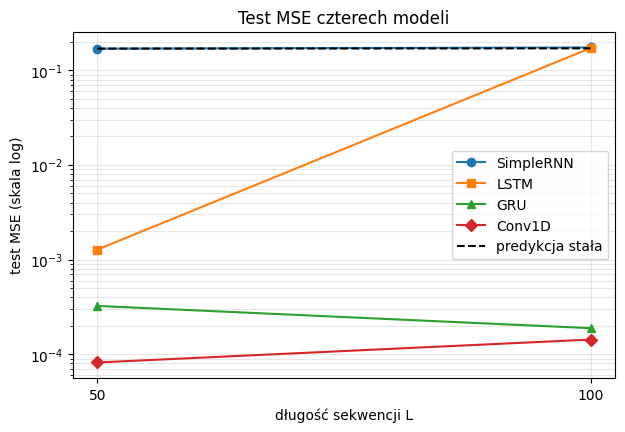

In [12]:
plt.figure(figsize=(7, 4.5))
for nazwa, znak in zip(MODELE, ["o-", "s-", "^-", "D-"]):
    mse_L = [next(w["mse"] for w in wyniki if w["model"] == nazwa
                  and w["L"] == L) for L in [50, 100]]
    plt.plot([50, 100], mse_L, znak, label=nazwa)
plt.plot([50, 100], [stala[50], stala[100]], "k--", label="predykcja stała")
plt.yscale("log")
plt.xticks([50, 100])
plt.xlabel("długość sekwencji L")
plt.ylabel("test MSE (skala log)")
plt.title("Test MSE czterech modeli")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.show()

Rys. 1: SimpleRNN przy obu długościach leży na linii predykcji stałej, LSTM skacze z 0,0013 do 0,172, a GRU i Conv1D zostają na poziomie około 0,0001–0,0003 przy obu długościach

### 3.5 Strata treningowa w kolejnych epokach, L = 100 (rys. 2)

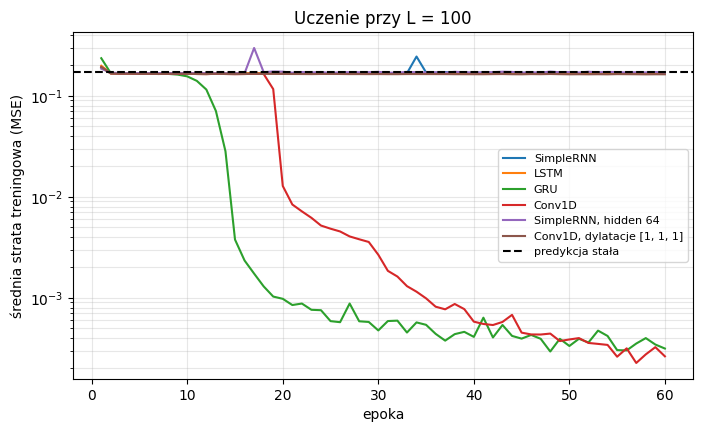

In [13]:
plt.figure(figsize=(8, 4.5))
for w in wyniki:
    if w["L"] == 100:
        plt.plot(range(1, EPOKI + 1), w["hist"], label=w["model"])
plt.axhline(stala[100], color="k", ls="--", label="predykcja stała")
plt.yscale("log")
plt.xlabel("epoka")
plt.ylabel("średnia strata treningowa (MSE)")
plt.title("Uczenie przy L = 100")
plt.grid(alpha=0.3, which="both")
plt.legend(fontsize=8)
plt.show()

Rys. 2: GRU wychodzi z płaskiego odcinka około 11.–15. epoki, a Conv1D z dylatacjami [1, 2, 4] około 19.–20. epoki, potem ich strata spada o trzy rzędy wielkości

SimpleRNN (oba rozmiary), LSTM i Conv1D z dylatacjami [1, 1, 1] przez całe 60 epok stoją na poziomie predykcji stałej, czyli przewidują w praktyce średnią

### 3.6 Przykład z dużym błędem i błąd a położenie znaczników

In [14]:
Xte100, Yte100 = dane[100][2].numpy(), dane[100][3].numpy().ravel()
kandydaci = [w for w in wyniki if w["L"] == 100 and w["model"] in MODELE
             and w["mse"] < 0.5 * stala[100]]
wybrany = (max(kandydaci, key=lambda w: w["mse"]) if kandydaci
           else next(w for w in wyniki if w["model"] == "SimpleRNN"
                     and w["L"] == 100))
blad = np.abs(wybrany["pred"] - Yte100)
i = int(np.argmax(blad))
t = np.nonzero(Xte100[i, :, 1])[0]
print(f"model: {wybrany['model']} (L = 100, test MSE {wybrany['mse']:.4f}), "
      f"przykład testowy nr {i}")
for k in t:
    print(f"znacznik w kroku {k + 1} -> wartość z kroku "
          f"{k + 1 - OPOZNIENIE}: {Xte100[i, k - OPOZNIENIE, 0]:.4f}")
print(f"prawidłowa suma {Yte100[i]:.4f} | predykcja {wybrany['pred'][i]:.4f}"
      f" | błąd {wybrany['pred'][i] - Yte100[i]:+.4f}")

model: GRU (L = 100, test MSE 0.0002), przykład testowy nr 629
znacznik w kroku 21 -> wartość z kroku 13: 0.8431
znacznik w kroku 90 -> wartość z kroku 82: 0.0041
prawidłowa suma 0.8472 | predykcja 0.9030 | błąd +0.0557


In [15]:
pierwszy = np.array([np.nonzero(x[:, 1])[0].min() + 1 - OPOZNIENIE
                     for x in Xte100])
przedzialy = [(1, 25), (26, 50), (51, 75), (76, 92)]
print("test MSE przy L = 100 według kroku pierwszej wskazanej wartości")
print(f"{'model':30s}" + "".join(f"{f'{a}-{b}':>10s}" for a, b in przedzialy))
print(f"{'liczba przykładów':30s}" + "".join(
    f"{int(((pierwszy >= a) & (pierwszy <= b)).sum()):10d}"
    for a, b in przedzialy))
for w in wyniki:
    if w["L"] == 100:
        e2 = (w["pred"] - Yte100) ** 2
        print(f"{w['model']:30s}" + "".join(
            f"{e2[(pierwszy >= a) & (pierwszy <= b)].mean():10.4f}"
            for a, b in przedzialy))

test MSE przy L = 100 według kroku pierwszej wskazanej wartości
model                               1-25     26-50     51-75     76-92
liczba przykładów                    463       345       155        37
SimpleRNN                         0.1832    0.1671    0.1652    0.1726
LSTM                              0.1802    0.1659    0.1620    0.1676
GRU                               0.0002    0.0002    0.0001    0.0003
Conv1D                            0.0001    0.0001    0.0003    0.0004
SimpleRNN, hidden 64              0.1789    0.1723    0.1575    0.1597
Conv1D, dylatacje [1, 1, 1]       0.1728    0.1656    0.1502    0.1663


Wybrany automatycznie przykład to najgorszy przykład testowy GRU, czyli modelu z największym błędem spośród tych, które przy L = 100 pobiły predykcję stałą

Znaczniki są w krokach 21 i 90, wskazują kroki 13 (0,8431) i 82 (0,0041), prawidłowa suma to 0,8472, a predykcja 0,9030, błąd +0,056

Tabela z podziałem na położenie pierwszej wskazanej wartości pokazuje, że GRU i Conv1D mają mały błąd niezależnie od położenia, a pozostałe modele mają we wszystkich przedziałach błąd na poziomie predykcji stałej

## 4. Analiza i interpretacja

Które modele pobiły predykcję stałą i co się stało przy dłuższym wejściu
- przy L = 50 LSTM, GRU i Conv1D zeszły o 2–3 rzędy wielkości poniżej predykcji stałej, SimpleRNN nie nauczył się nic
- przy L = 100 GRU i Conv1D dalej działają, błąd się praktycznie nie zmienił, a LSTM nie wyszedł z płaskiego odcinka w ciągu 60 epok i skończył na poziomie predykcji stałej
- już na walidacji przy L = 50 LSTM po 60 epokach miał 0,0461, czyli dużo więcej niż GRU i Conv1D (ok. 0,0005), więc uczy się tego zadania wyraźnie wolniej i przy L = 100 potrzebuje prawdopodobnie więcej epok, to wynik jednego ziarna i stałego budżetu epok, a nie dowód, że LSTM nie umie tego zadania
- SimpleRNN przy obu długościach nie ma szans, bo musi przez cały czas trzymać w stanie ostatnie 8 wartości i dodatkowo zapamiętać pierwszą wskazaną wartość na kilkadziesiąt kroków, a przy prostym RNN gradient z odległych kroków zanika

Co dał większy stan ukryty SimpleRNN i ile kosztował
- hidden 64 zamiast 32 nic nie dał: 0,1726 wobec 0,1745, oba wyniki są na poziomie predykcji stałej (0,1708)
- kosztował 3,7 razy więcej parametrów (4417 wobec 1185) i ok. 60% dłuższy trening (154 s wobec 95 s)
- problemem SimpleRNN nie jest za mała pamięć, tylko to, że nie da się go nauczyć przenoszenia informacji przez wiele kroków

Co dały dylatacje w Conv1D i ile kosztowały
- znacznik i wskazana wartość są 8 kroków od siebie, więc razem zajmują 9 pozycji
- przy dylatacjach [1, 2, 4] pole recepcyjne to 15 (pozycje od −7 do +7), więc pozycje między wskazaną wartością a znacznikiem widzą oba naraz, sieć może lokalnie policzyć „wartość, którą wskazuje znacznik”, a uśrednienie w czasie sumuje te wkłady, wynik 0,0001
- przy dylatacjach [1, 1, 1] pole to tylko 7 (od −3 do +3), żadna pozycja nie obejmuje jednocześnie znacznika i wskazanej próbki, więc model nie ma jak połączyć tych dwóch informacji i zostaje na poziomie predykcji stałej (0,1666)
- dylatacje nic nie kosztują: ta sama liczba parametrów (6465) i ten sam czas (98,3 s), zmienia się tylko to, które pozycje wejścia trafiają do filtra

Przykład z dużym błędem i sposób odczytu
- w najgorszym przykładzie GRU duża wartość 0,84 jest wskazana bardzo wcześnie (krok 13), a druga, prawie zerowa, prawie na końcu (krok 82, znacznik w kroku 90)
- GRU czyta wynik tylko z ostatniego stanu ukrytego, więc wartość z kroku 13 musi przetrwać w stanie przez ok. 87 kolejnych aktualizacji, w których przychodzą inne liczby do zignorowania
- predykcja jest zawyżona o 0,056, czyli pamięć tej wartości trochę się rozmyła po drodze, ale nadal jest to tylko kilka procent sumy
- Conv1D nie ma tego problemu, bo każdą parę wartość–znacznik wykrywa lokalnie, a uśrednienie w czasie nie zależy od tego, jak daleko od końca jest znacznik

Czas i parametry
- GRU był najwolniejszy (114 s i 232 s), mimo że ma mniej parametrów niż LSTM, to zależy od implementacji na CPU, a nie od liczby wag
- Conv1D ma najwięcej parametrów, ale liczy wszystkie pozycje naraz, więc trenuje się tak szybko jak LSTM

Ograniczenia
- każdy model trenowałem raz, z jednym ziarnem, więc szczególnie wynik LSTM przy L = 100 może zależeć od losowości i budżetu epok
- czasy są z jednego CPU, na GPU proporcje mogą być inne

## 5. Wnioski

- przy opóźnionym znaczniku zadanie jest dużo trudniejsze niż w ćwiczeniu, na ustawieniach z ćwiczenia żaden model się go nie nauczył, potrzeba było 5 razy więcej danych i 2 razy więcej epok
- GRU i Conv1D z dylatacjami [1, 2, 4] rozwiązują zadanie przy L = 50 i L = 100 z błędem około 0,0001–0,0003 wobec 0,17 dla predykcji stałej
- LSTM nauczył się zadania przy L = 50, ale przy L = 100 nie zdążył w 60 epokach, a SimpleRNN nie nauczył się go wcale
- większy stan ukryty SimpleRNN nic nie dał, a kosztował więcej parametrów i czasu, bo problemem jest uczenie odległych zależności, a nie pojemność
- w Conv1D liczy się pole recepcyjne: musi objąć znacznik i wskazaną próbkę naraz, przy [1, 1, 1] (pole 7) model nie działa, przy [1, 2, 4] (pole 15) działa, a koszt jest ten sam
- modele rekurencyjne z odczytem z ostatniego stanu muszą przenieść wczesne wartości przez całą sekwencję, a Conv1D z uśrednianiem łączy lokalne wykrycia i jest przez to mniej wrażliwy na długość